# İleri Yapay Sinir Ağları - Keşifsel Veri Analizi (EDA)

**Ad Soyad:** Muhammed Ali Akkuşcu  
**Öğrenci No:** 202551009024  
**Konu:** Spektral analiz ile bitki büyümesi ve boyut tahmini  
**Veri seti:** Eschikon Plant Stress Phenotyping Dataset (ETH Zürich, Autonomous Systems Lab)

Veri seti sayfası: https://projects.asl.ethz.ch/datasets/plant-stress-phenotyping-2018/  
Makale: Khanna et al. (2019), Plant Methods, 15:13 - https://doi.org/10.1186/s13007-019-0398-8  
İşleme kodları: https://github.com/ethz-asl/plant_stress_phenotyping

## EDA nedir, neden yapıyorum?

EDA (Exploratory Data Analysis), Türkçesiyle keşifsel veri analizi, model kurmadan önce veriyi tanıma aşaması. Veriye bakıyorum: kaç satır var, eksik değer var mı, değişkenler nasıl dağılmış, birbirleriyle ilişkili mi, garip (aykırı) değerler var mı. Bunları grafiklerle ve sayılarla inceleyip her adımda ne gördüğümü yazıyorum.

Benim amacım spektral bantlardan bitki boyunu ve kanopi örtüsünü tahmin eden bir sinir ağı kurmak. O yüzden EDA'da özellikle şunlara bakacağım: hedef değişkenler (boy, kanopi) nasıl davranıyor, spektral bantlar bunlarla ilişkili mi ve veri bu işe yetecek kadar temiz mi.

## 1. Kütüphaneler

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Veriyi yükleme

Veri setinin ham hali yaklaşık 4,6 GB (görüntüler ve nokta bulutları). Ben GitHub deposundaki `results` klasöründe bulunan işlenmiş dosyaları kullandım: `indicatorsAllMeans.mat` (her kutu ve her tarih için kanopi, hacim, boy ve 25 spektral bandın ortalaması) ve `yield.mat` (hasat ağırlıkları). Bu dosyaları tabloya çevirip CSV yaptım. Colab'da ayrıca dosya yüklemeye gerek kalmasın diye tabloları aşağıdaki hücrelere yapıştırdım.

Sütunlar:
- `kutu`: yetiştirme kutusu numarası (1-30)
- `tarih_no`, `gun`: ölçüm sırası ve ekimden sonraki gün sayısı
- `su`, `azot`, `ot`: kutuya uygulanan su, azot ve yabani ot koşulu
- `kanopi`: kanopi örtüsü, `hacim`: hacim tahmini, `boy`: ortalama bitki boyu (m)
- `MS1` ... `MS25`: hiperspektral kameranın 25 bandındaki yansıma değerleri

In [ ]:
VERI = """kutu,tarih_no,gun,su,azot,ot,kanopi,hacim,boy,MS1,MS2,MS3,MS4,MS5,MS6,MS7,MS8,MS9,MS10,MS11,MS12,MS13,MS14,MS15,MS16,MS17,MS18,MS19,MS20,MS21,MS22,MS23,MS24,MS25
1,1,0,Yeterli,Yüksek,Yok,0.054912,56.4021,0.0158433,0.121383,0.128108,0.14015,0.128934,0.0951497,0.273364,0.291283,0.291427,0.226266,0.114518,0.196451,0.269534,0.195934,0.161798,0.110181,0.122893,0.11725,0.152239,0.120786,0.117301,0.270067,0.217197,0.510083,0.338602,0.128093
1,2,12,Yeterli,Yüksek,Yok,0.0356951,25.822,0.0117855,0.307331,0.26685,0.309784,0.296021,0.238712,0.455185,0.338707,0.373641,0.289065,0.262269,0.362962,0.348706,0.362948,0.313421,0.317553,0.344001,0.273619,0.39456,0.302161,0.304937,0.549502,0.378794,0.660952,0.437533,0.307639
1,3,14,Yeterli,Yüksek,Yok,0.0270577,52.5667,0.0315148,0.275642,0.237395,0.284772,0.270856,0.197273,0.400438,0.296581,0.330405,0.254688,0.219694,0.316635,0.301089,0.31174,0.267689,0.263196,0.279122,0.215722,0.306533,0.239406,0.221887,0.43687,0.303938,0.499298,0.327205,0.229189
....

eschikon_veri.csv içerisinde Tüm veriler var
"""
HASAT = """kutu,yaprak_yas,yaprak_kuru,pancar_yas,pancar_kuru  
1,1537.7,119.61,444.96,54.5
2,1644.9,112.56,475.64,57.63
3,1493.5,114.56,537.01,76.13
4,1662.4,138.57,558.01,85.04
5,1327.7,111.34,435.43,74.96
6,1546.0,124.53,433.06,58.75
7,1503.4,100.86,536.57,65.13
8,1437.9,109.94,439.62,53.03
9,1629.9,188.23,547.18,86.48
10,1296.4,96.44,387.63,54.87
11,1478.5,132.33,488.76,70.11
12,1441.0,112.44,441.47,66.55
13,523.67,51.24,153.75,22.23
14,650.25,56.56,182.98,25.01
15,470.84,50.48,160.26,25.37
16,0.0,0.0,0.0,0.0
17,0.0,0.0,0.0,0.0
18,0.0,0.0,0.0,0.0
19,274.54,27.89,85.18,11.68
20,249.75,24.38,83.28,11.65
21,260.94,27.94,89.23,12.97
22,498.62,53.1,317.35,59.26
23,552.86,63.51,451.33,94.64
24,593.47,57.0,358.42,67.48
25,528.91,63.56,424.95,91.34
26,468.29,55.57,340.84,76.06
27,539.07,64.97,364.83,77.9
28,347.14,41.69,142.19,26.37
29,355.18,41.55,138.99,24.84
30,323.03,39.86,169.46,32.56
"""

df = pd.read_csv(StringIO(VERI))
hasat = pd.read_csv(StringIO(HASAT))
ms = ["MS" + str(i) for i in range(1, 26)]
print("Veri okundu:", df.shape, hasat.shape)

NameError: name 'pd' is not defined

## 3. Verinin ilk görünümü

In [3]:
print(df.shape)
df.head()

(480, 34)


,kutu,tarih_no,gun,su,azot,ot,kanopi,hacim,boy,MS1,...,MS16,MS17,MS18,MS19,MS20,MS21,MS22,MS23,MS24,MS25
0,1,1,0,Yeterli,Yüksek,Yok,0.054912,56.4021,0.015843,0.121383,...,0.122893,0.117250,0.152239,0.120786,0.117301,0.270067,0.217197,0.510083,0.338602,0.128093
1,1,2,12,Yeterli,Yüksek,Yok,0.035695,25.8220,0.011786,0.307331,...,0.344001,0.273619,0.394560,0.302161,0.304937,0.549502,0.378794,0.660952,0.437533,0.307639
2,1,3,14,Yeterli,Yüksek,Yok,0.027058,52.5667,0.031515,0.275642,...,0.279122,0.215722,0.306533,0.239406,0.221887,0.436870,0.303938,0.499298,0.327205,0.229189
3,1,4,18,Yeterli,Yüksek,Yok,0.111086,121.7970,0.017781,0.375862,...,0.378916,0.296730,0.427202,0.332079,0.315687,0.608831,0.420141,0.712418,0.473679,0.326824
4,1,5,21,Yeterli,Yüksek,Yok,0.111997,243.8070,0.035556,0.278518,...,0.273849,0.213056,0.297950,0.236793,0.217673,0.432651,0.303863,0.491282,0.338986,0.233949


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 34 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   kutu      480 non-null    int64  
 1   tarih_no  480 non-null    int64  
 2   gun       480 non-null    int64  
 3   su        480 non-null    str    
 4   azot      480 non-null    str    
 5   ot        480 non-null    str    
 6   kanopi    480 non-null    float64
 7   hacim     480 non-null    float64
 8   boy       480 non-null    float64
 9   MS1       480 non-null    float64
 10  MS2       480 non-null    float64
 11  MS3       480 non-null    float64
 12  MS4       480 non-null    float64
 13  MS5       480 non-null    float64
 14  MS6       480 non-null    float64
 15  MS7       480 non-null    float64
 16  MS8       480 non-null    float64
 17  MS9       480 non-null    float64
 18  MS10      480 non-null    float64
 19  MS11      480 non-null    float64
 20  MS12      480 non-null    float64
 21  MS13

Tabloda 480 satır ve 34 sütun var. Her satır bir kutunun bir tarihteki ölçümü; 30 kutu x 16 tarih = 480 yapıyor, yani sayılar ödevdeki veri tanımımla uyuşuyor. Sayısal sütunlar `float` olarak, `su`, `azot` ve `ot` sütunları metin olarak okunmuş. 

## 4. Eksik değer ve tekrar eden satır kontrolü

In [5]:
print("Toplam eksik değer:", df.isnull().sum().sum())
print("Tekrar eden satır:", df.duplicated().sum())
print("Her kutunun ölçüm sayısı:", df.groupby("kutu").size().unique())

Toplam eksik değer: 0
Tekrar eden satır: 0
Her kutunun ölçüm sayısı: [16]


Hiç eksik değer yok, tekrar eden satır da yok. Her kutu tam 16 kez ölçülmüş, yani zaman serisi dengeli. Veri temiz görünüyor. şunu not etmem lazım: bu tablo zaten görüntülerden hesaplanmış ortalama değerlerden oluşuyor, o yüzden ham görüntülerdeki sorunlar (gölge, kötü kutu tespiti gibi) burada görünmüyor olabilir.

## 5. Deney tasarımı: hangi kutuya ne uygulanmış?

In [6]:
kutular = df.drop_duplicates("kutu")[["kutu", "su", "azot", "ot"]]
print(kutular.groupby(["su", "azot", "ot"]).kutu.apply(list))
print()
print(kutular.su.value_counts().to_dict())
print(kutular.azot.value_counts().to_dict())
print(kutular.ot.value_counts().to_dict())

su       azot    ot       
Kısıtlı  Düşük   Yok          [28, 29, 30]
         Orta    Yok          [13, 14, 15]
                 Çok          [19, 20, 21]
Yeterli  Düşük   Az           [25, 26, 27]
                 Yok          [22, 23, 24]
         Orta    Yok             [4, 5, 6]
         Yüksek  Az              [7, 8, 9]
                 Sadece_ot    [16, 17, 18]
                 Yok             [1, 2, 3]
                 Çok          [10, 11, 12]
Name: kutu, dtype: object

{'Yeterli': 21, 'Kısıtlı': 9}
{'Yüksek': 12, 'Orta': 9, 'Düşük': 9}
{'Yok': 15, 'Az': 6, 'Çok': 6, 'Sadece_ot': 3}


 30 kutu 10 farklı uygulama grubuna ayrılmış ve her grupta 3 kutu (tekrar) var. Ama tasarım dengeli değil, bütün kombinasyonlar yok. Örneğin kısıtlı su sadece düşük ve orta azotla var, yüksek azotla hiç yok. Orta azotlu 9 kutunun 6'sı da kısıtlı sulu. Yani ileride azotun etkisine bakarsam su etkisi karışabilir. Yabani ot tarafında "Sadece_ot" grubunda sadece 3 kutu var ve bunlara şeker pancarı yerine sadece yabani ot ekilmiş gibi görünüyor.

## 6. İlk ölçüm gününün durumu (gün 0)

In [1]:
print(df[df.gun == 0][["kanopi", "hacim", "boy"]].describe().round(3))

d = df[df.gun > 0].copy()
print()
print("Gün 0 çıkarıldıktan sonra:", d.shape)

NameError: name 'df' is not defined

Ekim günü (gün 0) henüz bitki çıkmamış olmasına rağmen kanopi ortalaması 0.125, boy ortalaması 0.018 m çıkmış. Bu değerler bitkiden değil toprak ve kutu kenarlarından geliyor olmalı. Bu yüzden gün 0'ı analiz dışında bırakıyorum, ödevdeki gibi 30 kutu x 15 tarih = 450 gözlem kalıyor. Bundan sonraki bütün analizlerde `d` tablosunu kullanacağım.

## 7. Betimsel istatistikler

In [8]:
d[["kanopi", "hacim", "boy"]].describe().round(3)

,kanopi,hacim,boy
count,450.000,450.000,450.000
mean,0.577,5302.984,0.123
std,0.356,5283.951,0.104
min,0.006,0.106,0.000
25%,0.168,450.702,0.040
50%,0.683,3846.705,0.096
75%,0.915,8804.078,0.175
max,1.000,21914.500,0.441


In [9]:
d[ms].describe().round(2).T[["mean", "std", "min", "max"]]

,mean,std,min,max
MS1,0.49,0.17,0.21,1.17
MS2,0.43,0.14,0.18,1.02
MS3,0.53,0.18,0.20,1.22
MS4,0.50,0.17,0.19,1.17
MS5,0.34,0.10,0.16,0.79
MS6,0.66,0.16,0.28,1.06
MS7,0.49,0.11,0.23,0.75
MS8,0.53,0.11,0.24,0.81
MS9,0.45,0.12,0.17,0.72
MS10,0.38,0.11,0.17,0.88


In [10]:
yuksek = (d[ms] > 1).sum().sum()
print("Yansıma değeri 1'den büyük olan sayısı:", yuksek, "/", d[ms].size)

Yansıma değeri 1'den büyük olan sayısı: 109 / 11250


Kanopi 0.006 ile 1.0 arasında değişiyor. Sütun adı yüzde gibi yazılmış ama değerler 0-1 arası oran, yani %100 = 1.0. Kanopi ortalaması 0.58, boy ortalaması 0.123 m, en büyük boy 0.441 m. Hacim çok geniş aralıkta (0.1 ile yaklaşık 21900 arası), Spektral bantların ölçekleri birbirine yakın ama 11250 değerin 109'unda yansıma 1'in üstüne çıkmış. Yansıma fiziksel olarak 1'i geçmemeli, kalibrasyondan veya ışık farkından kaynaklanan küçük bir hata olabilir. Oranı yaklaşık %1 olduğu için  silmiyorum 

## 8. Hedef değişkenlerin dağılımı (histogram)

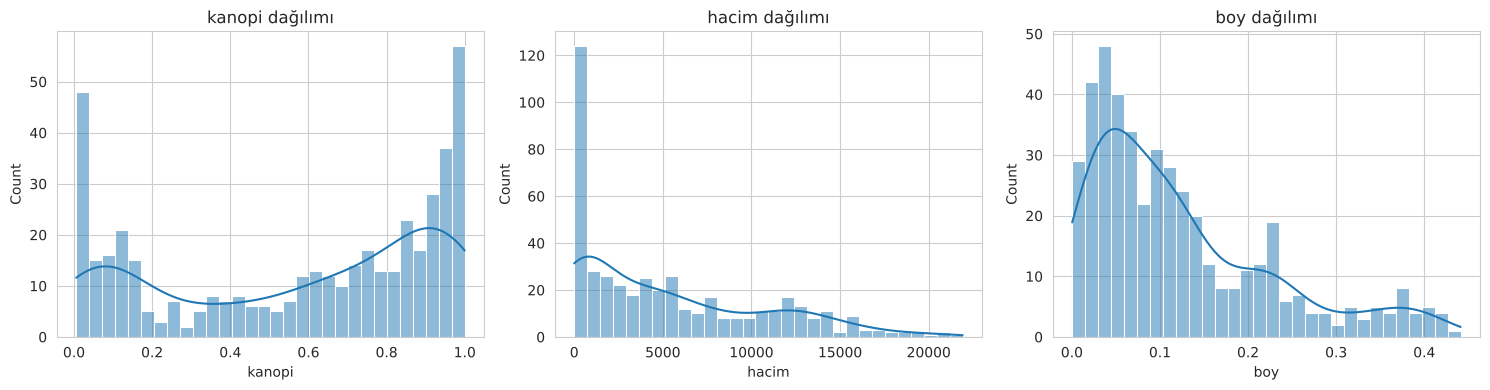

kanopi   -0.40
hacim     0.89
boy       1.17
dtype: float64
Kanopi 0.95'in üstünde olan gözlem sayısı: 70


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, c in enumerate(["kanopi", "hacim", "boy"]):
    sns.histplot(d[c], bins=30, kde=True, ax=ax[i])
    ax[i].set_title(c + " dağılımı")
plt.tight_layout()
plt.show()

print(d[["kanopi", "hacim", "boy"]].skew().round(2))
print("Kanopi 0.95'in üstünde olan gözlem sayısı:", (d.kanopi > 0.95).sum())

Boy ve hacim sağa çarpık (çarpıklık 1.17 ve 0.89), yani çok sayıda küçük değer ve az sayıda büyük değer var. Bunun sebebi ilk tarihlerde bitkilerin küçük olması. Kanopi ise tam tersi, 1'e yakın yerde yığılma var (450 gözlemin 70'inde 0.95'in üstünde). Bitkiler kutuyu tamamen kapatınca kanopi daha fazla artamıyor. Bu yüzden kanopiyi tahmin etmek ilk dönemlerde kolay ama sonraki dönemlerde bilgi vermiyor olabilir. Boy için ileride log dönüşümü deneyebilirim.

## 9. Tarihlere göre boy dağılımı (kutu grafiği)

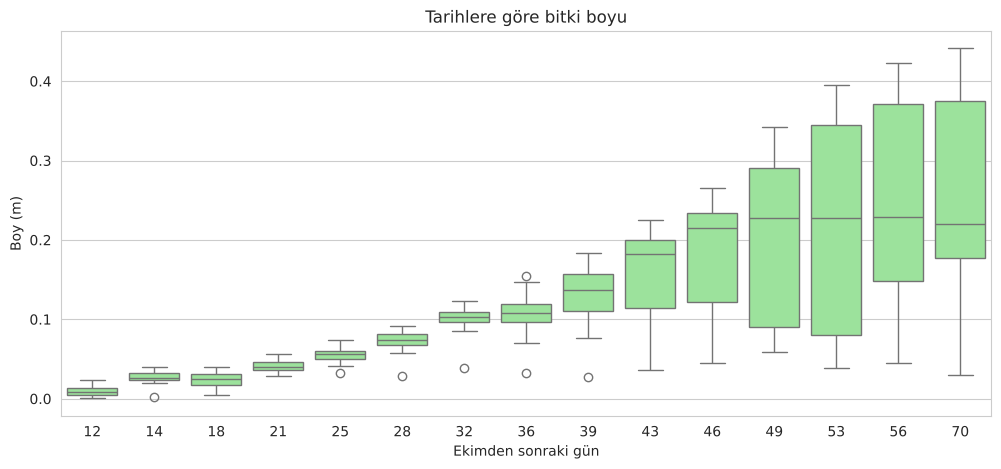

gun
12    0.006
14    0.008
18    0.009
21    0.007
25    0.009
28    0.012
32    0.015
36    0.024
39    0.036
43    0.058
46    0.073
49    0.101
53    0.128
56    0.118
70    0.113
Name: boy, dtype: float64
IQR kuralına göre aykırı boy sayısı: 15


In [12]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=d, x="gun", y="boy", color="lightgreen")
plt.xlabel("Ekimden sonraki gün")
plt.ylabel("Boy (m)")
plt.title("Tarihlere göre bitki boyu")
plt.show()

print(d.groupby("gun").boy.std().round(3))

q1, q3 = d.boy.quantile([0.25, 0.75])
print("IQR kuralına göre aykırı boy sayısı:", (d.boy > q3 + 1.5 * (q3 - q1)).sum())

 Kutuların yayılımı zamanla büyüyor. Boyun standart sapması ilk tarihlerde 0.006-0.009 civarındayken 53. günde 0.128'e çıkıyor. Yani bitkiler büyüdükçe kutular arasındaki fark da artıyor, uygulamaların etkisi geç tarihlerde ortaya çıkıyor. Bütün veriye IQR kuralını uygulayınca 15 aykırı boy değeri çıkıyor ama bunlar hata değil, en iyi büyüyen kutuların geç tarihleri. Bu yüzden bunları silmeyeceğim.

## 10. Zaman içinde büyüme

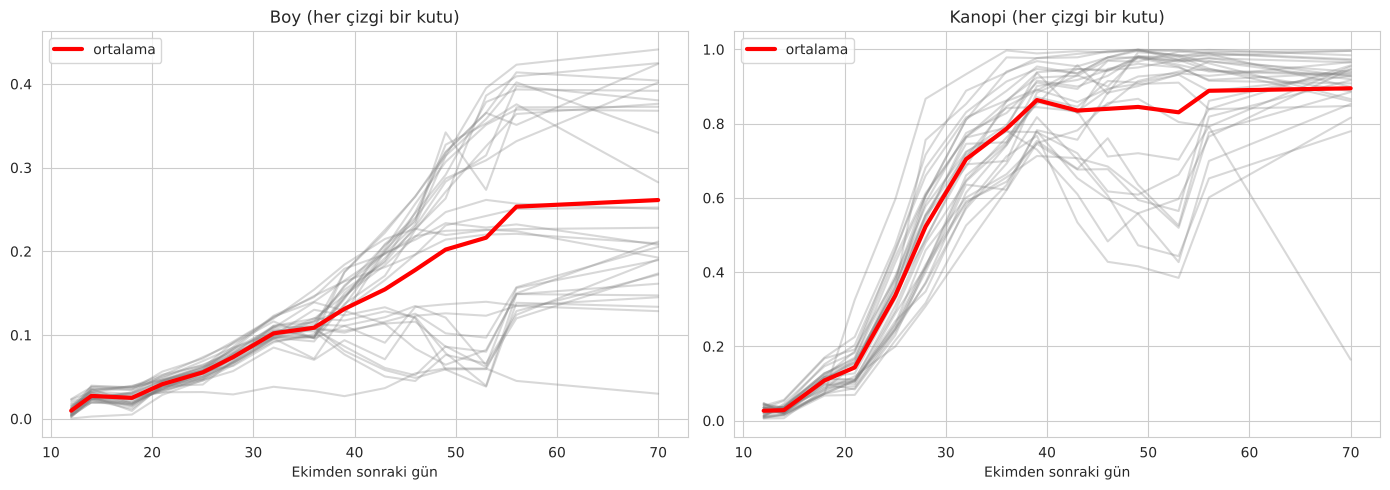

     kanopi      hacim    boy
gun                          
12    0.027     13.511  0.010
14    0.028     47.472  0.027
18    0.108    166.806  0.025
21    0.143    360.024  0.041
25    0.337   1149.541  0.055
28    0.523   2337.541  0.074
32    0.704   4457.416  0.102
36    0.786   5122.694  0.109
39    0.863   6419.238  0.131
43    0.835   7935.230  0.155
46    0.840   8991.951  0.178
49    0.845   9794.486  0.202
53    0.831   9553.831  0.216
56    0.889  12623.578  0.253
70    0.895  10571.440  0.261


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for k in range(1, 31):
    s = d[d.kutu == k]
    ax[0].plot(s.gun, s.boy, color="gray", alpha=0.3)
    ax[1].plot(s.gun, s.kanopi, color="gray", alpha=0.3)

ort = d.groupby("gun")[["boy", "kanopi"]].mean()
ax[0].plot(ort.index, ort.boy, color="red", linewidth=3, label="ortalama")
ax[1].plot(ort.index, ort.kanopi, color="red", linewidth=3, label="ortalama")
ax[0].set_title("Boy (her çizgi bir kutu)")
ax[1].set_title("Kanopi (her çizgi bir kutu)")
for a in ax:
    a.set_xlabel("Ekimden sonraki gün")
    a.legend()
plt.tight_layout()
plt.show()

print(d.groupby("gun")[["kanopi", "hacim", "boy"]].mean().round(3))

 Kanopi çok hızlı artıyor: 12. günde ortalama 0.03, 39. günde 0.86. Ondan sonra 0.83-0.90 arasında dalgalanarak sabit kalıyor, yani doygunluğa ulaşıyor. Boy ise bu dönemde artmaya devam ediyor: 39. günde 0.13 m, 56. günde 0.25 m, 70. günde 0.26 m. Demek ki 39. günden sonra büyümeyi kanopi değil boy anlatıyor. Hacim de 56. günde 12624 iken 70. günde 10571'e düşmüş, bunun nedenini bilmiyorum. İlk tarihlerde (12-21. gün) boy değerleri düzensiz (0.010, 0.027, 0.025, 0.041), fideler çok küçük olduğu için ölçüm gürültülü olabilir. Gri çizgilerden kutular arasında büyük farklar olduğu da görülüyor.

## 11. Uygulama gruplarına göre boy gelişimi

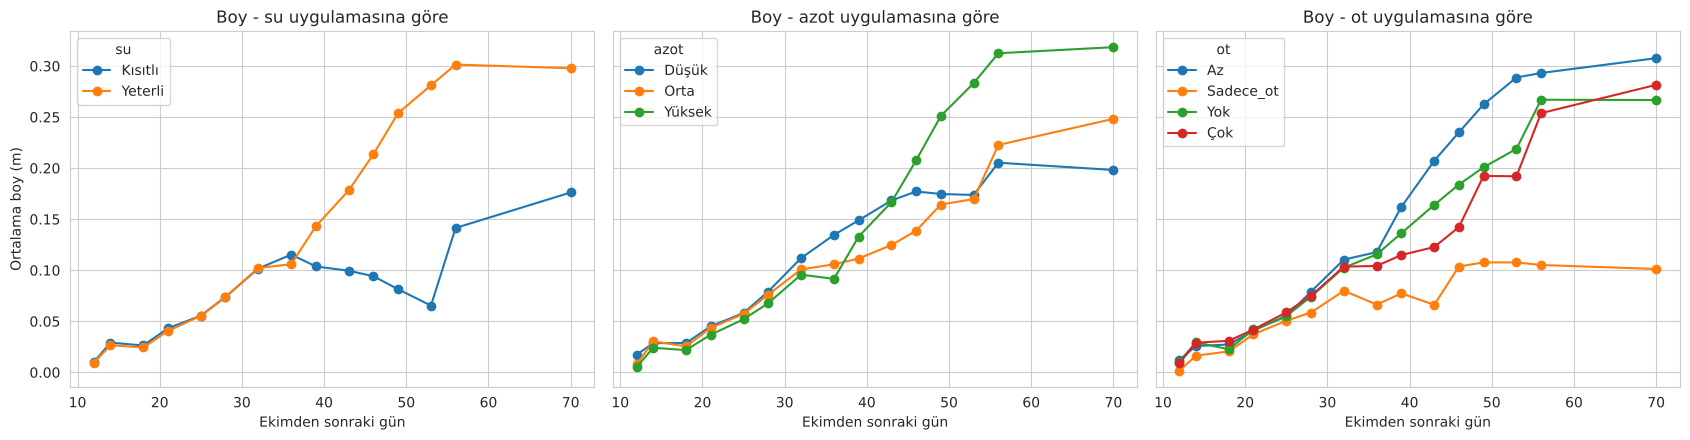

           boy  kanopi
su                    
Kısıtlı  0.176   0.895
Yeterli  0.298   0.895

          boy  kanopi
azot                 
Düşük   0.198   0.877
Orta    0.248   0.925
Yüksek  0.318   0.886

             boy  kanopi
ot                      
Az         0.308   0.922
Sadece_ot  0.101   0.719
Yok        0.267   0.892
Çok        0.282   0.963



In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for i, g in enumerate(["su", "azot", "ot"]):
    d.groupby(["gun", g]).boy.mean().unstack().plot(ax=ax[i], marker="o")
    ax[i].set_title("Boy - " + g + " uygulamasına göre")
    ax[i].set_xlabel("Ekimden sonraki gün")
ax[0].set_ylabel("Ortalama boy (m)")
plt.tight_layout()
plt.show()

son = d[d.gun == 70]
for g in ["su", "azot", "ot"]:
    print(son.groupby(g)[["boy", "kanopi"]].mean().round(3))
    print()

 Su uygulaması en belirgin fark yaratan etken. İlk tarihlerde iki grup aynı, 36. günden sonra ayrılıyor ve 70. günde yeterli sulu kutuların boyu ortalama 0.298 m, kısıtlı sulu olanlarınki 0.176 m. Kısıtlı sulu grupta boy 36. günden sonra düşüp 53. günde 0.065 m'ye iniyor, sonra tekrar yükseliyor. Bunun nedenini (solma ve sonra sulama olabilir) veriden çıkaramıyorum, makaleye bakıp kontrol etmem gerekiyor. Azotta 70. günde boy düşük, orta, yüksek sırasıyla 0.198, 0.248, 0.318 m ve beklenen sıraya uyuyor. Ama orta azot grubu bazı tarihlerde düşük azottan bile düşük çıkıyor, bunun sebebi yukarıda yazdığım gibi orta azotlu kutuların çoğunun kısıtlı sulu olması. Yabani otta durum net değil. "Sadece_ot" grubu çok kısa (0.101 m) ama "Çok" ve "Az" gruplar "Yok" grubundan düşük değil. Boy 3 boyutlu nokta bulutundan hesaplandığı için yabani otlar da ölçüme karışıyor olabilir. Ayrıca 56. günde neredeyse bütün gruplarda küçük bir sıçrama var, o günkü ölçüm koşulu farklı olmuş olabilir.

## 12. Spektral bantların zamanla ve su stresiyle değişimi

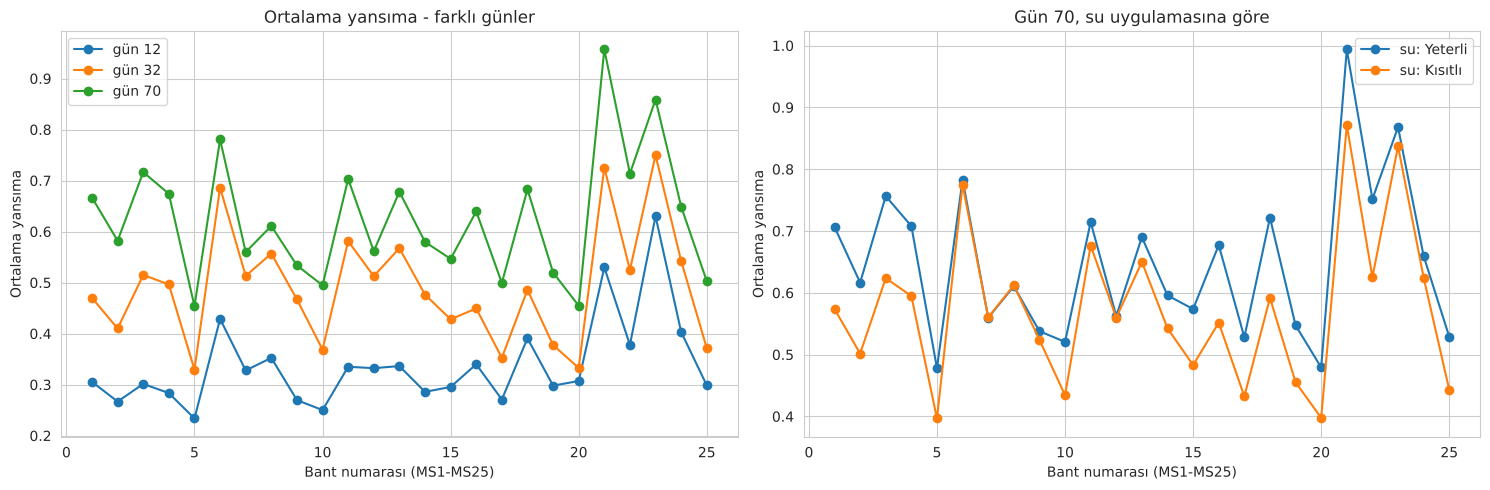

{'MS1': 0.47, 'MS21': 0.73}


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
x = range(1, 26)
for g in [12, 32, 70]:
    ax[0].plot(x, d[d.gun == g][ms].mean().values, marker="o", label="gün " + str(g))
ax[0].set_title("Ortalama yansıma - farklı günler")

son = d[d.gun == 70]
for s in ["Yeterli", "Kısıtlı"]:
    ax[1].plot(x, son[son.su == s][ms].mean().values, marker="o", label="su: " + s)
ax[1].set_title("Gün 70, su uygulamasına göre")

for a in ax:
    a.set_xlabel("Bant numarası (MS1-MS25)")
    a.set_ylabel("Ortalama yansıma")
    a.legend()
plt.tight_layout()
plt.show()

print(d[d.gun == 32][ms].mean()[["MS1", "MS21"]].round(2).to_dict())

**Yorum:** Bitkiler büyüdükçe yansıma artıyor. Örneğin MS21'de ortalama yansıma 12. günde 0.53, 70. günde 0.96. Sağdaki grafikte su stresinin bazı bantları etkilediği görülüyor: MS1'de yeterli sulu kutular 0.71, kısıtlı sulu kutular 0.57 ve MS21'de 0.99'a karşı 0.87. Ama MS6 gibi bazı bantlarda iki grup hemen hemen aynı (0.78 ve 0.77). Yani her bant su stresine aynı derecede duyarlı değil. 32. günde değerler ikisinin arasında (MS21 için 0.73). Bir şey daha dikkatimi çekti: çizgi düzgün bir bitki spektrumu gibi görünmüyor, bantlar arasında inip çıkıyor. Bu yüzden MS numaraları dalga boyu sırasında değil gibi. Yaklaşık her 5 bantta bir benzer bir iniş çıkış tekrar ediyor (5, 10, 15, 20. bantlar düşük); kameranın 5x5 mozaik filtre yapısıyla ilgili olabilir ama bundan emin değilim. Tabloda dalga boyları yazmadığı için NDVI ve NDRE'yi hesaplayamadım. Bantları numaralarıyla kullanacağım.

## 13. Hedef değişkenler arasındaki ilişki

In [16]:
print(d[["kanopi", "hacim", "boy"]].corr().round(2))

        kanopi  hacim   boy
kanopi    1.00   0.84  0.78
hacim     0.84   1.00  0.97
boy       0.78   0.97  1.00


**Yorum:** Boy ile hacim arasında 0.97 gibi çok yüksek bir korelasyon var. Hacim de boy gibi 3 boyutlu nokta bulutundan hesaplandığı için bu şaşırtıcı değil. Bu yüzden boyu tahmin ederken hacmi girdi olarak kullanmamalıyım, çünkü model bir nevi cevabı görmüş olur. Kanopi ile boy arasında 0.78 var, ilişkili ama aynı şey değiller.

## 14. Spektral bantlar arasındaki korelasyon

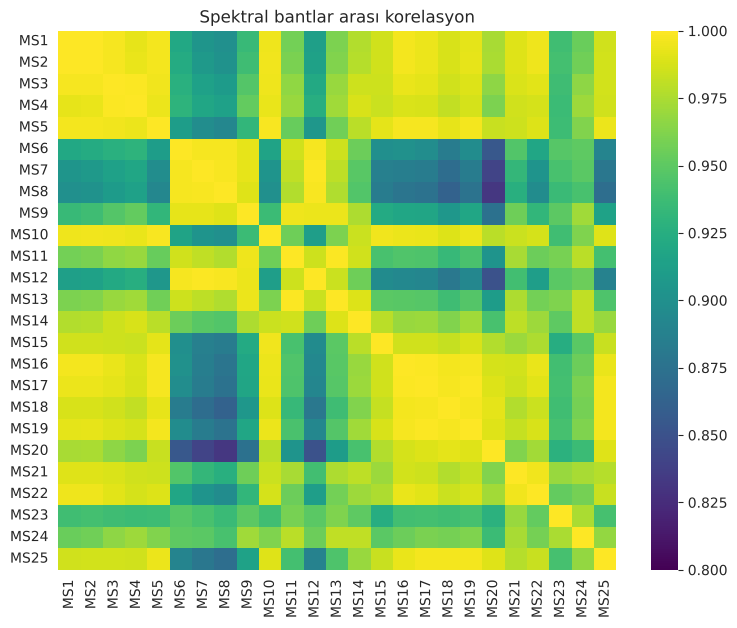

Ortalama korelasyon: 0.96  En düşük: 0.83


In [17]:
kor = d[ms].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(kor, cmap="viridis", vmin=0.8, vmax=1)
plt.title("Spektral bantlar arası korelasyon")
plt.show()

ust = kor.values[np.triu_indices(25, 1)]
print("Ortalama korelasyon:", ust.mean().round(2), " En düşük:", ust.min().round(2))

**Yorum:** 25 bandın birbiriyle korelasyonu çok yüksek, ortalaması 0.96 ve en düşüğü bile 0.83. Yani bantlar neredeyse aynı bilgiyi taşıyor (çoklu doğrusal bağıntı). Sinir ağı bununla çalışabilir ama gereksiz girdi sayısı, 30 kutuluk küçük bir veride aşırı öğrenme riskini artırır.

## 15. Bantların boy ve kanopi ile ilişkisi

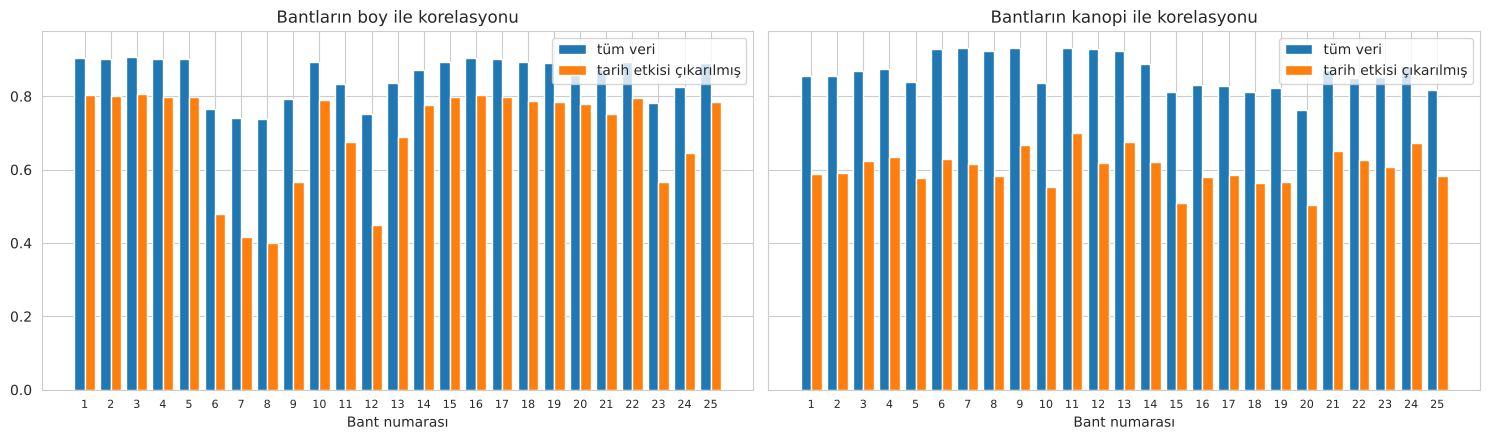

Boy, tüm veri: 0.74 - 0.91
Boy, tarih içi: 0.4 - 0.81
Kanopi, tüm veri: 0.76 - 0.93
Kanopi, tarih içi: 0.5 - 0.7
En iyi bant (boy): MS3  (kanopi): MS11


In [18]:
# Önce bütün veride korelasyon
genel_boy = d[ms].corrwith(d.boy)
genel_kan = d[ms].corrwith(d.kanopi)

# Sonra her tarihin ortalamasını çıkararak (zamanın etkisini kaldırarak)
w = d.copy()
for c in ms + ["boy", "kanopi"]:
    w[c] = w[c] - w.groupby("gun")[c].transform("mean")
tarih_boy = w[ms].corrwith(w.boy)
tarih_kan = w[ms].corrwith(w.kanopi)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
idx = np.arange(25)
ax[0].bar(idx - 0.2, genel_boy.values, 0.4, label="tüm veri")
ax[0].bar(idx + 0.2, tarih_boy.values, 0.4, label="tarih etkisi çıkarılmış")
ax[0].set_title("Bantların boy ile korelasyonu")
ax[1].bar(idx - 0.2, genel_kan.values, 0.4, label="tüm veri")
ax[1].bar(idx + 0.2, tarih_kan.values, 0.4, label="tarih etkisi çıkarılmış")
ax[1].set_title("Bantların kanopi ile korelasyonu")
for a in ax:
    a.set_xticks(idx)
    a.set_xticklabels(range(1, 26), fontsize=8)
    a.set_xlabel("Bant numarası")
    a.legend()
plt.tight_layout()
plt.show()

print("Boy, tüm veri:", genel_boy.min().round(2), "-", genel_boy.max().round(2))
print("Boy, tarih içi:", tarih_boy.min().round(2), "-", tarih_boy.max().round(2))
print("Kanopi, tüm veri:", genel_kan.min().round(2), "-", genel_kan.max().round(2))
print("Kanopi, tarih içi:", tarih_kan.min().round(2), "-", tarih_kan.max().round(2))
print("En iyi bant (boy):", tarih_boy.idxmax(), " (kanopi):", tarih_kan.idxmax())

**Yorum:** Bütün veriye bakınca bantların boyla korelasyonu 0.74-0.91, kanopiyle 0.76-0.93 arasında, yani çok yüksek görünüyor. Ama bunun büyük kısmı zamandan geliyor, çünkü hem bantlar hem boy zamanla artıyor. Her tarihin ortalamasını çıkarıp bakınca boyda korelasyon 0.40-0.81'e, kanopide 0.50-0.70'e düşüyor. Yine de ilişki hâlâ güçlü. Boy için en iyi bant MS3 (0.81), kanopi için MS11 (0.70). Bu yüzden modelin başarısını değerlendirirken dikkatli olmalıyım: model sadece zamanı öğrenip iyi sonuç veriyormuş gibi görünebilir. Gün bilgisini girdiye koyarsam bunu ayrıca raporlamam lazım.

## 16. Dağılım grafikleri (scatter)

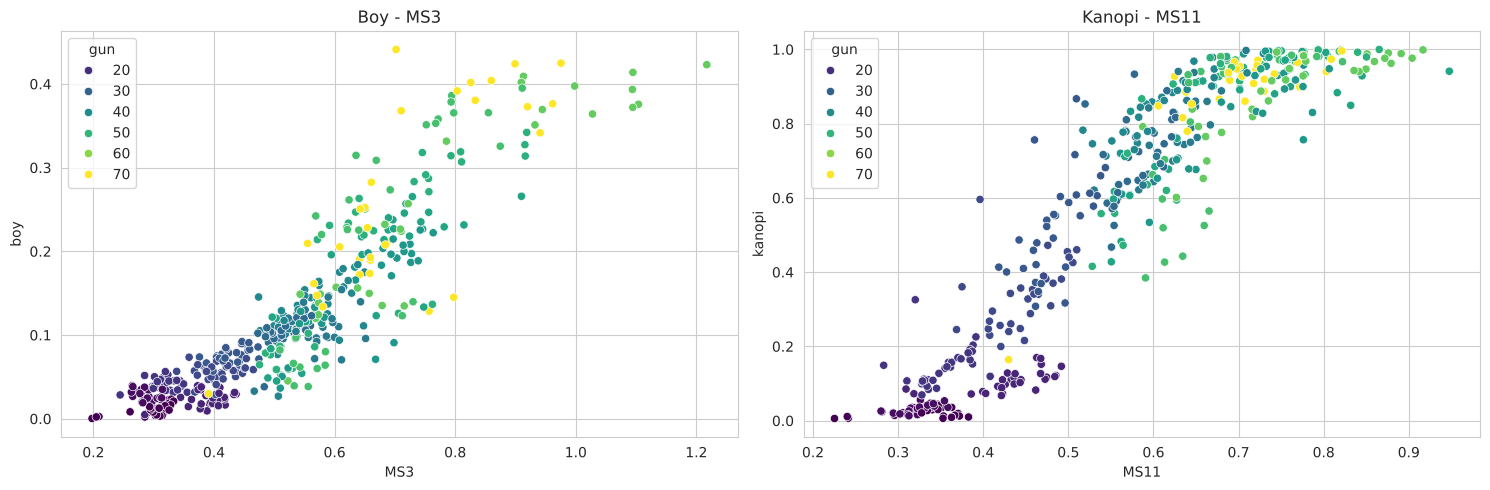

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=d, x="MS3", y="boy", hue="gun", palette="viridis", ax=ax[0])
ax[0].set_title("Boy - MS3")
sns.scatterplot(data=d, x="MS11", y="kanopi", hue="gun", palette="viridis", ax=ax[1])
ax[1].set_title("Kanopi - MS11")
plt.tight_layout()
plt.show()

**Yorum:** Boy ile MS3 arasında artan ve yaklaşık doğrusal bir ilişki var. Ama MS3 0.6'nın üstüne çıkınca nokta bulutu açılıyor; örneğin MS3 0.7 civarında boy 0.1 ile 0.4 arasında değişebiliyor. Renklere bakınca geç tarihlerin (sarı ve açık yeşil) sağ üstte toplandığı görülüyor, yani ilişkinin bir kısmı zamandan geliyor. Kanopi ile MS11 arasındaki ilişki doğrusal değil, S şeklinde: önce hızlı artıyor, MS11 0.7'yi geçince kanopi 1'e yapışıyor ve yansıma artsa da kanopi artmıyor. İlk tarihlerdeki koyu mor noktaların bir kısmı (MS11 0.45 civarı, kanopi 0.1) genel çizginin dışında kalıyor. Doğrusal bir modelden çok sinir ağı gibi doğrusal olmayan bir model mantıklı görünüyor.

## 17. Boyut indirgeme: PCA

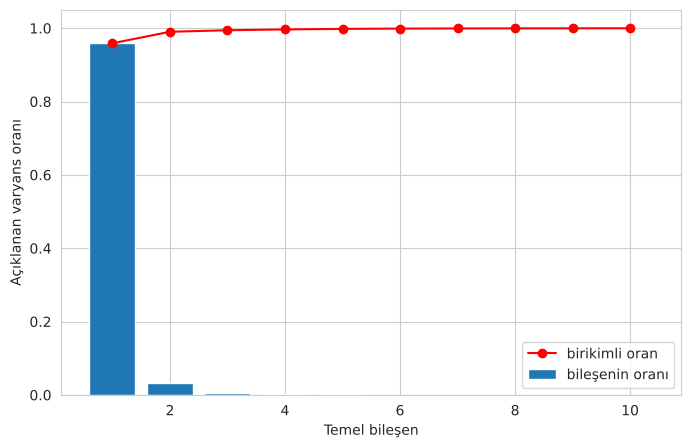

[0.959 0.031 0.004] -> ilk 2 bileşen: 0.99


In [20]:
olcekli = StandardScaler().fit_transform(d[ms])
pca = PCA().fit(olcekli)
oran = pca.explained_variance_ratio_

plt.figure(figsize=(8, 5))
plt.bar(range(1, 11), oran[:10], label="bileşenin oranı")
plt.plot(range(1, 11), oran.cumsum()[:10], color="red", marker="o", label="birikimli oran")
plt.xlabel("Temel bileşen")
plt.ylabel("Açıklanan varyans oranı")
plt.legend()
plt.show()

print(oran[:3].round(3), "-> ilk 2 bileşen:", oran[:2].sum().round(3))

**Yorum:** İlk temel bileşen verideki değişimin %95.9'unu, ikincisi %3.1'ini açıklıyor; ilk ikisi birlikte yaklaşık %99. Yani 25 bant aslında hemen hemen tek bir yönde değişiyor. Bu yön büyük ihtimalle bitkinin gelişmesiyle (yaprak örtüsü ve zaman) ilgili. Bu da bir önceki korelasyon sonucuyla uyumlu. Modelde çok sayıda bant yerine birkaç bileşen kullanmayı deneyebilirim. Yine de küçük farkları taşıyan sonraki bileşenler stres bilgisi içeriyor olabilir, o yüzden hepsini atmadan karşılaştırmak gerekir.

## 18. Hasat (biyokütle) verisi

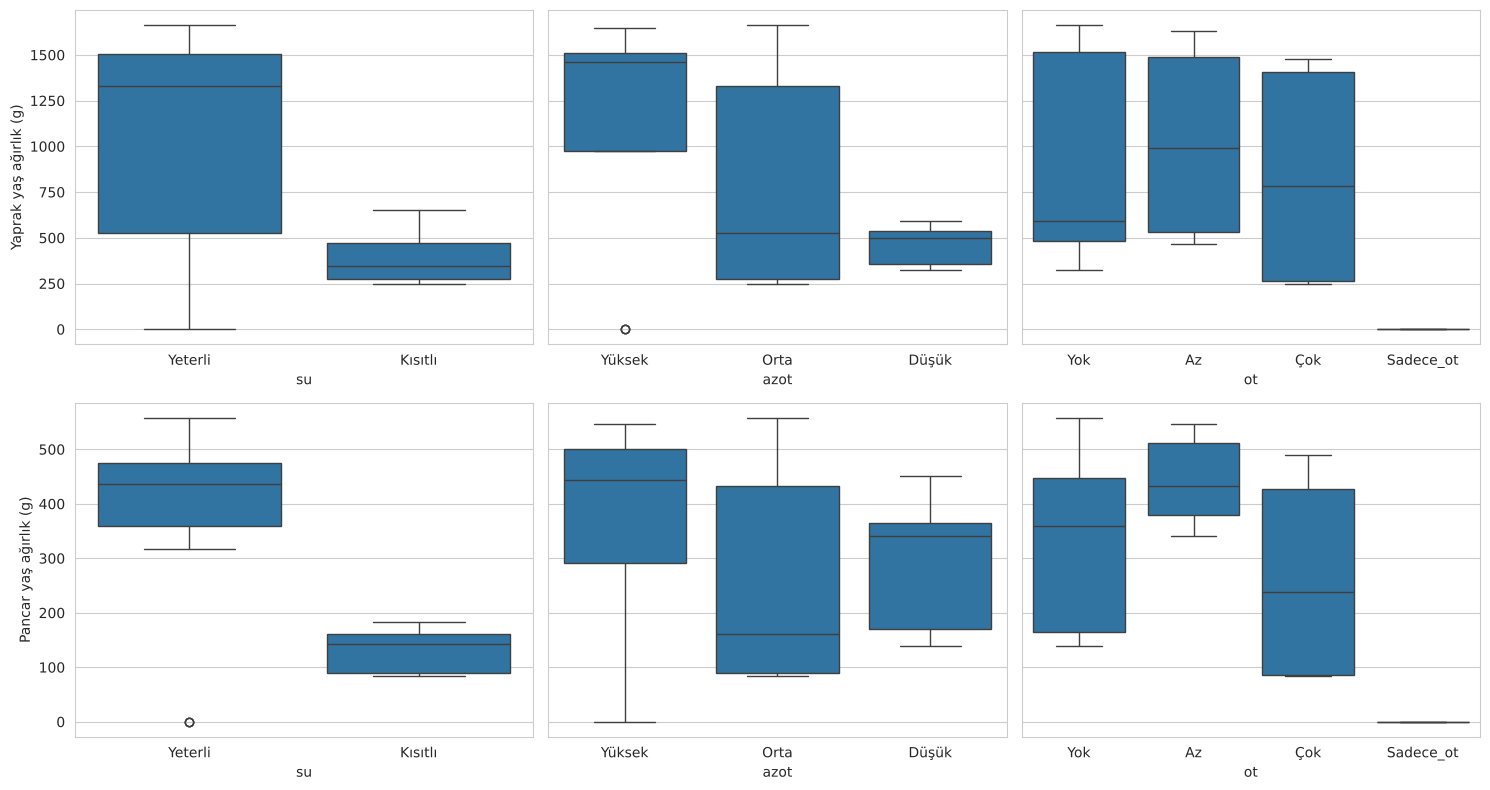

         yaprak_yas  pancar_yas
su                             
Kısıtlı       384.0       134.0
Yeterli      1009.0       380.0

        yaprak_yas  pancar_yas
azot                          
Düşük        467.0       301.0
Orta         774.0       242.0
Yüksek      1122.0       358.0

           yaprak_yas  pancar_yas
ot                               
Az             1018.0       442.0
Sadece_ot         0.0         0.0
Yok             902.0       331.0
Çok             834.0       263.0



In [21]:
h = hasat.merge(kutular, on="kutu")

fig, ax = plt.subplots(2, 3, figsize=(15, 8), sharey="row")
for i, g in enumerate(["su", "azot", "ot"]):
    sns.boxplot(data=h, x=g, y="yaprak_yas", ax=ax[0, i])
    sns.boxplot(data=h, x=g, y="pancar_yas", ax=ax[1, i])
ax[0, 0].set_ylabel("Yaprak yaş ağırlık (g)")
ax[1, 0].set_ylabel("Pancar yaş ağırlık (g)")
plt.tight_layout()
plt.show()

for g in ["su", "azot", "ot"]:
    print(h.groupby(g)[["yaprak_yas", "pancar_yas"]].mean().round(0))
    print()

**Yorum:** Yeterli sulu kutularda yaprak yaş ağırlığı ortalama 1009 g, kısıtlı sulu olanlarda 384 g. Pancar kökünde de 380 g'a karşı 134 g var, yani su stresi hasadı çok düşürmüş. "Sadece_ot" kutularında hasat sıfır, çünkü şeker pancarı yok. Azotta yaprak ağırlığı düşükten yükseğe 467, 774, 1122 g diye artıyor. Fakat pancar kökünde düşük azot (301 g) orta azottan (242 g) yüksek çıkıyor. Bunun sebebi muhtemelen orta azotlu kutuların çoğunun kısıtlı sulu olması, yani yine su etkisi karışıyor. Hasat ölçümü kutu başına tek değer olduğu için sadece 30 gözlemimiz var.

## 19. Son tarihteki boy hasatla ilişkili mi?

             boy  kanopi  hacim  yaprak_yas  pancar_yas
boy         1.00    0.46   0.90        0.95        0.87
kanopi      0.46    1.00   0.68        0.28        0.29
hacim       0.90    0.68   1.00        0.79        0.79
yaprak_yas  0.95    0.28   0.79        1.00        0.88
pancar_yas  0.87    0.29   0.79        0.88        1.00


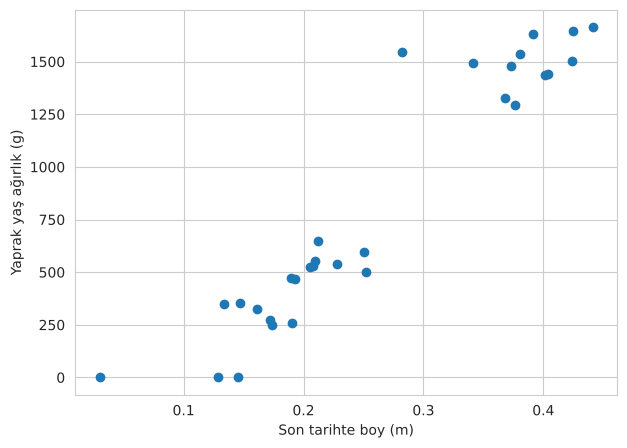

In [22]:
son = d[d.gun == 70][["kutu", "boy", "kanopi", "hacim"]].merge(hasat, on="kutu")
print(son[["boy", "kanopi", "hacim", "yaprak_yas", "pancar_yas"]].corr().round(2))

plt.figure(figsize=(7, 5))
plt.scatter(son.boy, son.yaprak_yas)
plt.xlabel("Son tarihte boy (m)")
plt.ylabel("Yaprak yaş ağırlık (g)")
plt.show()

**Yorum:** Son tarihteki boy ile yaprak yaş ağırlığı arasında 0.95, pancar ağırlığıyla 0.87 korelasyon var. Kanopi ise yaprak ağırlığıyla sadece 0.28 korelasyonlu, çünkü kanopi doygunluğa ulaşmış. Bu bana boyun gerçek biyokütleyi çok daha iyi temsil ettiğini gösteriyor. Dolayısıyla spektral veriden boyu tahmin etmek anlamlı bir hedef gibi duruyor.

## 20. Şüpheli kutular

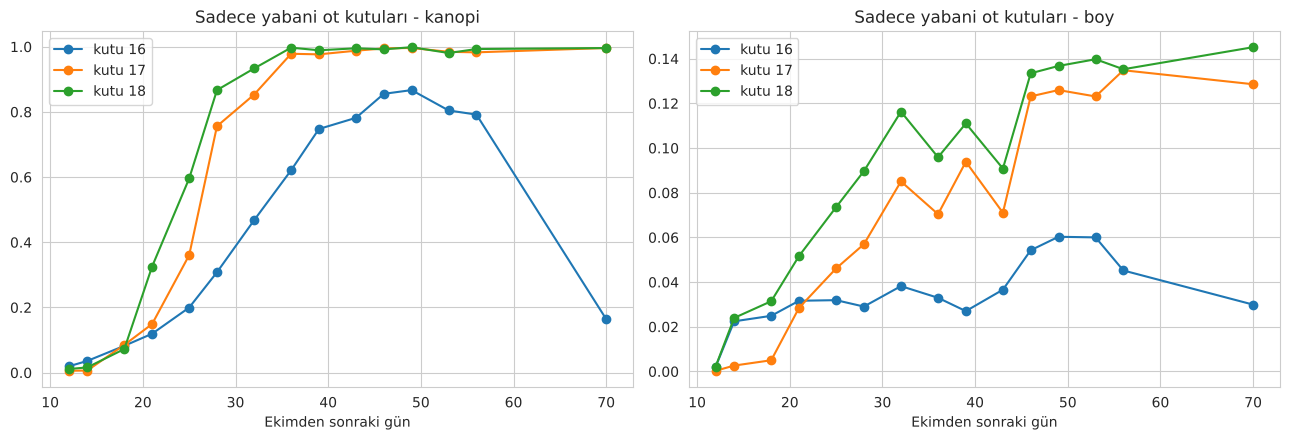

     gun  kanopi    boy     hacim
253   53   0.804  0.060  3076.640
254   56   0.792  0.045  2242.890
255   70   0.164  0.030   295.689


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for k in [16, 17, 18]:
    s = d[d.kutu == k]
    ax[0].plot(s.gun, s.kanopi, marker="o", label="kutu " + str(k))
    ax[1].plot(s.gun, s.boy, marker="o", label="kutu " + str(k))
ax[0].set_title("Sadece yabani ot kutuları - kanopi")
ax[1].set_title("Sadece yabani ot kutuları - boy")
for a in ax:
    a.set_xlabel("Ekimden sonraki gün")
    a.legend()
plt.tight_layout()
plt.show()

print(d[(d.kutu == 16) & (d.gun >= 53)][["gun", "kanopi", "boy", "hacim"]].round(3))

**Yorum:** Aynı uygulamayı alan 16, 17 ve 18 numaralı kutular arasında son tarihte büyük bir fark var. Kutu 16'nın kanopisi 56. günde 0.79 iken 70. günde 0.16'ya düşmüş, 17 ve 18'de ise 1'e yakın kalmış. Bunun gerçekten bitkilerin ölmesinden mi yoksa ölçüm hatasından (kutu tespiti, kamera) mı kaynaklandığını veriden söyleyemiyorum. Modelde bu satır sonuçları bozabilir. Modeli bu satırla ve bu satır olmadan karşılaştırmayı düşünüyorum.

## 21. Genel değerlendirme

Bu çalışmada Eschikon veri setinin işlenmiş göstergelerini (30 kutu, 15 ölçüm tarihi, 450 gözlem) inceledim. Veri temiz: eksik değer ve tekrar eden satır yok. Ancak küçük bir veri, 30 kutudan oluşuyor ve aynı kutunun farklı tarihleri birbirine çok benziyor. Bu yüzden eğitim ve test ayrımını ödevdeki planıma uygun olarak kutu bazında yapmam şart, aksi halde test sonuçları olduğundan iyi çıkar.

Hedef değişkenlere bakınca kanopinin 39. günden sonra doygunluğa ulaştığını, boyun ise sonuna kadar arttığını gördüm. Boy hem büyümeyi hem de hasat ağırlığını daha iyi temsil ediyor, o yüzden ana hedefim boy olacak, kanopi ikinci hedef olarak kalabilir. Spektral bantlar birbiriyle çok yüksek korelasyonlu (ortalama 0.96) ve bunların varyansının neredeyse %99'u iki bileşende toplanıyor. Bantların boy ve kanopiyle ilişkisi zaman etkisi çıkarılınca da sürüyor (boy için 0.81'e, kanopi için 0.70'e kadar), yani spektral veriden tahmin yapmak mümkün görünüyor. Ama zaman etkisi güçlü olduğu için modelin sadece günü öğrenmediğinden emin olmam gerekecek.

Dikkat etmem gereken noktalar: (1) hacim boyla aynı 3 boyutlu ölçümden geldiği için girdi olarak kullanılmayacak, (2) uygulama grupları dengesiz ve su, azot etkileri birbirine karışıyor, (3) 109 yansıma değeri 1'in üstünde, (4) kutu 16'nın son ölçümü şüpheli, (5) bantların dalga boyları tabloda olmadığı için NDVI ve NDRE hesaplayamadım.

Sonraki adımda sırasıyla MLP (temel model), sonra veri yapısı elverirse 1D-CNN ve LSTM modellerini kurup MAE, RMSE ve R² ile kutu bazlı çapraz doğrulama kullanarak karşılaştıracağım.